Describe the clinical corpus and compute case-specific rubric composition.


In [1]:
import os, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 200)


In [2]:
ds = P.dataset()
print('cases:', len(ds))
comp = []
for col in ['Type', 'Genealogy', 'Age Group', 'Sub Clinical Specialties']:
    vc = ds[col].value_counts()
    for k, v in vc.items():
        comp.append({'field': col, 'level': k, 'n': int(v), 'share': v / len(ds)})
comp = pd.DataFrame(comp)
display(comp)
P.save_table(comp, 'clinical_corpus_composition.csv', index=False)


cases: 229


,field,level,n,share
0,Type,Requires emergent care,84,0.366812
1,Type,Requires non-emergent care,81,0.353712
2,Type,Self-care appropriate,64,0.279476
3,Genealogy,AI,151,0.659389
4,Genealogy,checker,43,0.187773
5,Genealogy,msd,35,0.152838
6,Age Group,young age (25-44),78,0.340611
7,Age Group,middle age (45-60),44,0.192140
8,Age Group,elderly age (>60),37,0.161572
9,Age Group,children (<15),36,0.157205


saved tables/clinical_corpus_composition.csv (32 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\clinical_corpus_composition.csv'

In [3]:
print('distinct specialties:', ds['Sub Clinical Specialties'].nunique())
print('distinct reference diagnoses (Diagnosis_vulgar):', ds['Diagnosis_vulgar'].nunique())
print('distinct ICD-10 labels (Diagnosis10):', ds['Diagnosis10'].nunique())
print('Vignette_race filled:', int(ds['Vignette_race'].notna().sum()))
for c in ['Review of Systems', 'Past Medical History', 'Physical Examination', 'Test Results']:
    filled = ds[c].notna() & ds[c].astype(str).str.strip().ne('') & ds[c].astype(str).ne('nan')
    print(f"{c:<22} filled: {int(filled.sum())}  by genealogy: {ds.loc[filled, 'Genealogy'].value_counts().to_dict()}")
display(pd.crosstab(ds['Genealogy'], ds['Type'], margins=True))


distinct specialties: 20
distinct reference diagnoses (Diagnosis_vulgar): 197
distinct ICD-10 labels (Diagnosis10): 179
Vignette_race filled: 5
Review of Systems      filled: 35  by genealogy: {'msd': 35}
Past Medical History   filled: 35  by genealogy: {'msd': 35}
Physical Examination   filled: 35  by genealogy: {'msd': 35}
Test Results           filled: 33  by genealogy: {'msd': 33}


Type,Requires emergent care,Requires non-emergent care,Self-care appropriate,All
Genealogy,,,,
AI,53,47,51,151
checker,14,16,13,43
msd,17,18,0,35
All,84,81,64,229


In [4]:
arms = P.load_main_arms()
ref = arms['P-base']
ct = ref['case_text'].astype(str)
lens = pd.DataFrame({'chars': ct.str.len(), 'words': ct.map(lambda s: len(s.split())), 'Genealogy': ref['Genealogy']})
display(lens.describe().round(0))
display(lens.groupby('Genealogy')[['chars', 'words']].median())


,chars,words
count,229.0,229.0
mean,1241.0,191.0
std,1337.0,202.0
min,165.0,25.0
25%,599.0,96.0
50%,759.0,120.0
75%,940.0,144.0
max,6045.0,950.0


,chars,words
Genealogy,,
AI,765.0,120.0
checker,462.0,74.0
msd,4230.0,637.0


In [5]:
same = {}
for n in arms:
    common = arms[n].index.intersection(ref.index)
    same[n] = bool((arms[n].loc[common, 'Criterion'] == ref.loc[common, 'Criterion']).all())
print('identical Criterion column across arms:', all(same.values()), same)


identical Criterion column across arms: True {'gpt': True, 'qwen': True, 'deepseekv4': True, 'deepseekv4pro': True, 'gemini': True, 'glm': True, 'kimi': True, 'P-base': True, 'P-base/org-ds': True, 'P-base/org-qwen': True, 'P-base/org-gemini': True, 'P-weak': True, 'P-mixed': True, 'P-strong': True, 'homog gpt': True, 'homog qwen': True, 'homog deepseekv4': True, 'homog gemini': True}


In [6]:
def parse_criteria(text):
    blocks = re.split('\\n?\\[(\\d+)\\]\\n', str(text).replace('\r\n', '\n').strip())
    out = []
    for i in range(1, len(blocks), 2):
        body = blocks[i + 1]
        pts = re.search('points:\\s*(-?\\d+)', body)
        tag = re.search('tags:\\s*\\[(.+?)\\]', body)
        crit = re.search('criterion:\\s*\\n([\\s\\S]+)', body)
        out.append({'cid': int(blocks[i]), 'points': int(pts.group(1)) if pts else 0, 'axis': tag.group(1).strip().strip('\'"').replace('axis:', '') if tag else None, 'text': crit.group(1).strip() if crit else ''})
    return out
rows = []
for v, t in ref['Criterion'].items():
    for c in parse_criteria(t):
        c['Vignette'] = v
        rows.append(c)
rub = pd.DataFrame(rows)
per_case = rub.groupby('Vignette').agg(n=('cid', 'size'), n_pen=('points', lambda s: (s < 0).sum()), max_pos=('points', lambda s: s[s > 0].sum()))
print('criteria total:', len(rub))
print('per case: min/median/max =', per_case.n.min(), per_case.n.median(), per_case.n.max())
print('penalty criteria:', int((rub.points < 0).sum()), f'({(rub.points < 0).mean():.1%})')
print('positive weights range:', rub.loc[rub.points > 0, 'points'].min(), '..', rub.loc[rub.points > 0, 'points'].max())
print('negative weights range:', rub.loc[rub.points < 0, 'points'].min(), '..', rub.loc[rub.points < 0, 'points'].max())
print('max attainable positive points per case: median', per_case.max_pos.median(), 'IQR', per_case.max_pos.quantile(0.25), '-', per_case.max_pos.quantile(0.75))
summ = pd.DataFrame([('cases', len(ds)), ('specialties', ds['Sub Clinical Specialties'].nunique()), ('reference_diagnoses', ds['Diagnosis_vulgar'].nunique()), ('input_chars_median', lens.chars.median()), ('input_words_median', lens.words.median()), ('criteria_total', len(rub)), ('criteria_per_case_min', per_case.n.min()), ('criteria_per_case_median', per_case.n.median()), ('criteria_per_case_max', per_case.n.max()), ('penalty_criteria', int((rub.points < 0).sum())), ('penalty_share', (rub.points < 0).mean()), ('max_pos_points_median', per_case.max_pos.median()), ('max_pos_points_q25', per_case.max_pos.quantile(0.25)), ('max_pos_points_q75', per_case.max_pos.quantile(0.75))], columns=['quantity', 'value'])
P.save_table(summ, 'clinical_corpus_summary.csv', index=False)


criteria total: 3270
per case: min/median/max = 12 14.0 16
penalty criteria: 924 (28.3%)
positive weights range: 2 .. 10
negative weights range: -10 .. -2
max attainable positive points per case: median 68.0 IQR 61.0 - 73.0
saved tables/clinical_corpus_summary.csv (14 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\clinical_corpus_summary.csv'

In [7]:
ax_tab = rub.assign(pos=rub.points.clip(lower=0)).groupby('axis').agg(criteria=('cid', 'size'), penalties=('points', lambda s: (s < 0).sum()), pos_points=('pos', 'sum'))
ax_tab['share_criteria'] = ax_tab.criteria / ax_tab.criteria.sum()
ax_tab['share_pos_points'] = ax_tab.pos_points / ax_tab.pos_points.sum()
ax_tab = ax_tab.sort_values('criteria', ascending=False)
display(ax_tab.round(3))
P.save_table(ax_tab, 'clinical_rubric_axes.csv')


,criteria,penalties,pos_points,share_criteria,share_pos_points
axis,,,,,
accuracy,1001,435,4352,0.306,0.283
completeness,977,178,4903,0.299,0.318
urgency,457,195,1914,0.140,0.124
uncertainty,308,39,1492,0.094,0.097
reasoning,285,39,1731,0.087,0.112
communication_quality,242,38,1007,0.074,0.065


saved tables/clinical_rubric_axes.csv (6 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\clinical_rubric_axes.csv'

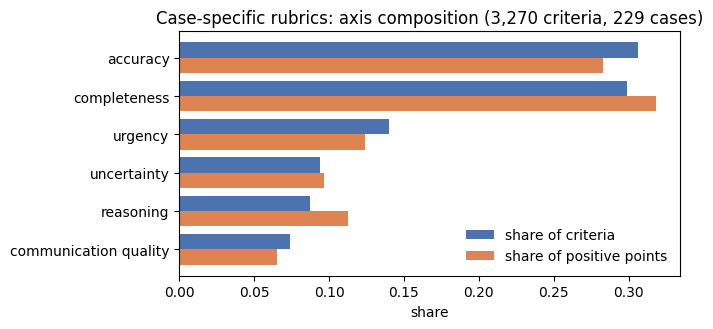

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
order = ax_tab.index.tolist()
y = np.arange(len(order))
ax.barh(y - 0.2, ax_tab.share_criteria, height=0.4, label='share of criteria', color='#4C72B0')
ax.barh(y + 0.2, ax_tab.share_pos_points, height=0.4, label='share of positive points', color='#DD8452')
ax.set_yticks(y)
ax.set_yticklabels([o.replace('_', ' ') for o in order])
ax.invert_yaxis()
ax.set_xlabel('share')
ax.set_title('Case-specific rubrics: axis composition (3,270 criteria, 229 cases)')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_clinical_rubric_axes.png'), dpi=200)


In [9]:
ex = rub[rub.Vignette == ref.index[1]]
print(ref.iloc[1]['Diagnosis_vulgar'], '|', ref.iloc[1]['Type'])
for _, r in ex.iterrows():
    print(f'[{r.cid:>2}] {r.points:+3d} {r.axis:<22} {r.text[:150]}')


Peptic Ulcer Disease | Requires non-emergent care
[ 1] +10 accuracy               Identifies NSAID-induced peptic ulcer disease as the leading diagnosis based on 3 years of daily naproxen use, gnawing epigastric pain worse on empty 
[ 2]  +9 completeness           Recommends discontinuation or substantial reduction of naproxen and proposes safer alternatives for osteoarthritis (e.g., topical NSAIDs, acetaminophe
[ 3]  +8 completeness           Recommends initiation or optimization of a proton pump inhibitor for ulcer healing and discusses the rationale for adequate duration of therapy.
[ 4]  +7 completeness           Recommends Helicobacter pylori testing (urea breath test, stool antigen, or biopsy if endoscoped) given the high prevalence of dual etiology and impac
[ 5]  +7 uncertainty            Presents a reasonable differential including PUD, gastritis, functional dyspepsia, GERD, and gastric malignancy, with reasoning grounded in the case.
[ 6]  +7 urgency                Educates t

In [10]:
import statsmodels.formula.api as smf
long = []
for n, d in arms.items():
    long.append(pd.DataFrame({'arm': n, 'case': d.index, 'y': d['Judge_score'].values, 'Type': d['Type'].values, 'Genealogy': d['Genealogy'].values, 'spec': d['Sub Clinical Specialties'].values, 'age': d['Age Group'].values}))
long = pd.concat(long, ignore_index=True)
tot = ((long.y - long.y.mean()) ** 2).sum()
for f in ['C(Type)', 'C(Genealogy)', 'C(spec)', 'C(age)', 'C(arm)', 'C(case)']:
    r2 = smf.ols('y ~ ' + f, long).fit().rsquared
    print(f'{f:<14} R2 = {r2:.3f}')


C(Type)        R2 = 0.007
C(Genealogy)   R2 = 0.019
C(spec)        R2 = 0.024
C(age)         R2 = 0.011
C(arm)         R2 = 0.321


C(case)        R2 = 0.346
